<a href="https://colab.research.google.com/github/ariyan378/Machine-Learning-Projects/blob/main/Flight_Price_Prediction_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Flight Price Prediction**



**INTRODUCTION**

The objective of the study is to analyse the flight booking dataset obtained from “Ease My Trip” website and to conduct various statistical hypothesis tests in order to get meaningful information from it. The 'Linear Regression' statistical algorithm would be used to train the dataset and predict a continuous target variable. 'Easemytrip' is an internet platform for booking flight tickets, and hence a platform that potential passengers use to buy tickets. A thorough study of the data will aid in the discovery of valuable insights that will be of enormous value to passengers.


**DATA COLLECTION AND METHODOLOGY**

Octoparse scraping tool was used to extract data from the website. Data was collected in two parts: one for economy class tickets and another for business class tickets. A total of 300261 distinct flight booking options was extracted from the site. Data was collected for 50 days, from February 11th to March 31st, 2022. Data source was secondary data and was collected from Ease my trip website.

**DATASET**

Dataset contains information about flight booking options from the website Easemytrip for flight travel between India's top 6 metro cities. There are 300261 datapoints and 11 features in the cleaned dataset.

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [58]:

url = "https://raw.githubusercontent.com/ariyan378/Machine-Learning-Projects/main/Clean_Dataset_Flight_price.csv"


df = pd.read_csv(url)

df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


# **Data Exploration**

In [59]:
df.shape

(300153, 12)

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


**FEATURES**

The various features of the cleaned dataset are explained below:
 1) **Airline**: The name of the airline company is stored in the airline column. It is a categorical feature having 6 different airlines.
 2) **Flight**: Flight stores information regarding the plane's flight code. It is a categorical feature.
  3) **Source City**: City from which the flight takes off. It is a categorical feature having 6 unique cities.
   4) **Departure Time**: This is a derived categorical feature obtained created by grouping time periods into bins. It stores information about the departure time and have 6 unique time labels.
   5) **Stops**: A categorical feature with 3 distinct values that stores the number of stops between the source and destination cities.
   6) **Arrival Time**: This is a derived categorical feature created by grouping time intervals into bins. It has six distinct time labels and keeps information about the arrival time.
   7) **Destination City**: City where the flight will land. It is a categorical feature having 6 unique cities.
   8) **Class**: A categorical feature that contains information on seat class; it has two distinct values: Business and Economy.
   9) **Duration**: A continuous feature that displays the overall amount of time it takes to travel between cities in hours.
   10. **Days Left**: This is a derived characteristic that is calculated by subtracting the trip date by the booking date.
  11) **Price**: Target variable stores information of the ticket price.

In [61]:
df.columns.tolist()

['Unnamed: 0',
 'airline',
 'flight',
 'source_city',
 'departure_time',
 'stops',
 'arrival_time',
 'destination_city',
 'class',
 'duration',
 'days_left',
 'price']

In [62]:
df.describe(include='all')

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
count,300153.000000,300153,300153,300153,300153,300153,300153,300153,300153,300153.000000,300153.000000,300153.000000
unique,NaN,6,1561,6,6,3,6,6,2,NaN,NaN,NaN
top,NaN,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy,NaN,NaN,NaN
freq,NaN,127859,3235,61343,71146,250863,91538,59097,206666,NaN,NaN,NaN
mean,150076.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.221021,26.004751,20889.660523
std,86646.852011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.191997,13.561004,22697.767366
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.830000,1.000000,1105.000000
25%,75038.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.830000,15.000000,4783.000000
50%,150076.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.250000,26.000000,7425.000000
75%,225114.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.170000,38.000000,42521.000000


In [63]:
for col in df.columns:
    print(df[col].dtype)

int64
object
object
object
object
object
object
object
object
float64
int64
int64


In [64]:
df.drop(columns='Unnamed: 0' , inplace=True)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


In [66]:
df.isna().sum()

,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0
days_left,0


In [67]:
df.duplicated().sum()

np.int64(0)

In [68]:
df['duration']

,duration
0,2.17
1,2.33
2,2.17
3,2.25
4,2.33
...,...
300148,10.08
300149,10.42
300150,13.83
300151,10.00


# **Univariate Analysis**

**Duration**

In [69]:
df['duration'].head(3)

,duration
0,2.17
1,2.33
2,2.17


In [70]:
fig = px.histogram(df,
                   x=df['duration'],
                   marginal='box',
                   color_discrete_sequence=['green', 'grey'],
                   title='Flight Duration')
fig.update_layout(bargap=0.1)
fig.show()

**Days Left**

In [71]:
df['days_left']

,days_left
0,1
1,1
2,1
3,1
4,1
...,...
300148,49
300149,49
300150,49
300151,49


In [72]:
fig = px.histogram(df,
                   x=df['days_left'],
                   marginal='box',
                   title='Days Left')
fig.update_layout(bargap=0.1)
fig.show()

**Class**

In [73]:
df['class'].unique()

array(['Economy', 'Business'], dtype=object)

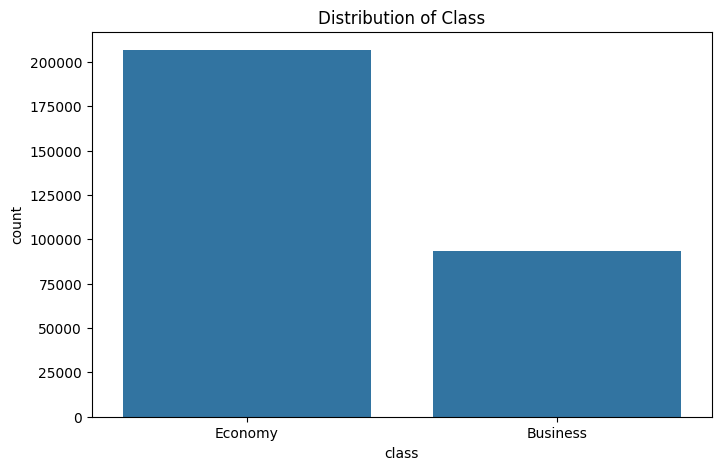

In [74]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['class'])

plt.title("Distribution of Class")
plt.show()

**Stops**

In [75]:
df['stops'].unique()

array(['zero', 'one', 'two_or_more'], dtype=object)

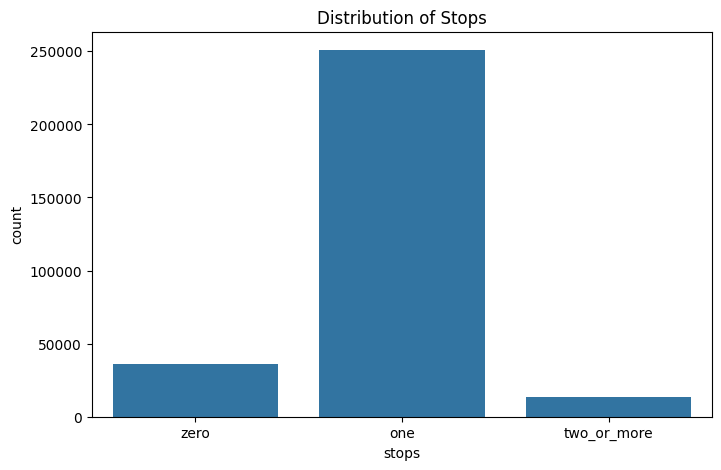

In [76]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['stops'])

plt.title("Distribution of Stops")
plt.show()

**Source City**

In [77]:
df['source_city'].unique()

array(['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai'],
      dtype=object)

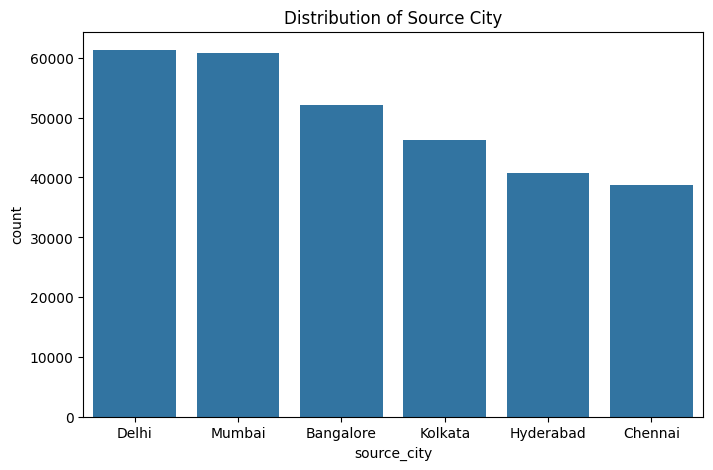

In [78]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['source_city'])

plt.title("Distribution of Source City")
plt.show()

**Destination City**

In [79]:
df['destination_city'].unique()

array(['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi'],
      dtype=object)

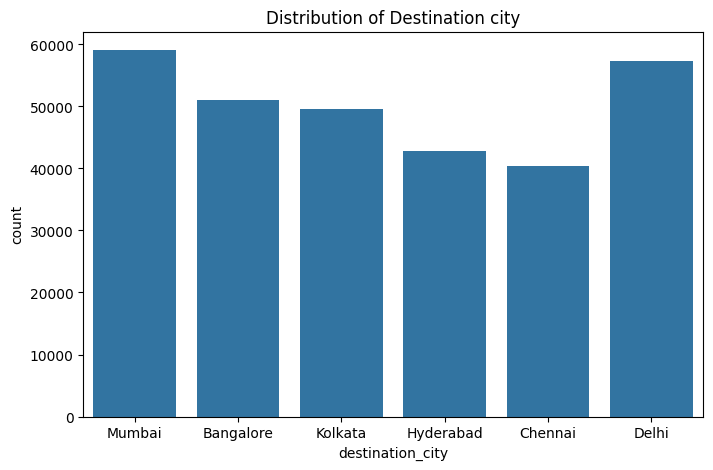

In [80]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['destination_city'])

plt.title("Distribution of Destination city")
plt.show()

**Arrival Time**

In [81]:
df['arrival_time'].unique()

array(['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening',
       'Late_Night'], dtype=object)

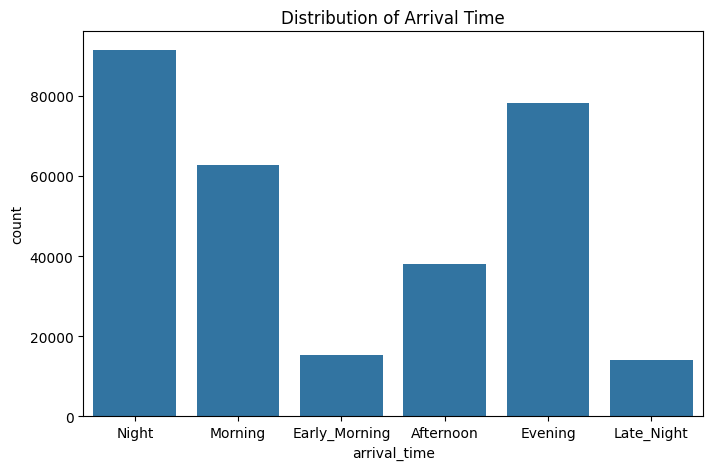

In [82]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['arrival_time'])

plt.title("Distribution of Arrival Time")
plt.show()

**Departure time**

In [83]:
df['departure_time'].unique()

array(['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night',
       'Late_Night'], dtype=object)

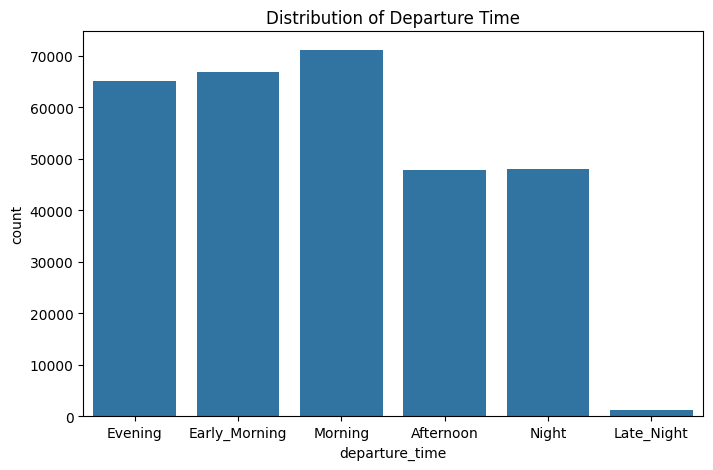

In [84]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['departure_time'])

plt.title("Distribution of Departure Time")
plt.show()

**airline**

In [85]:
df['airline'].unique()

array(['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo',
       'Air_India'], dtype=object)

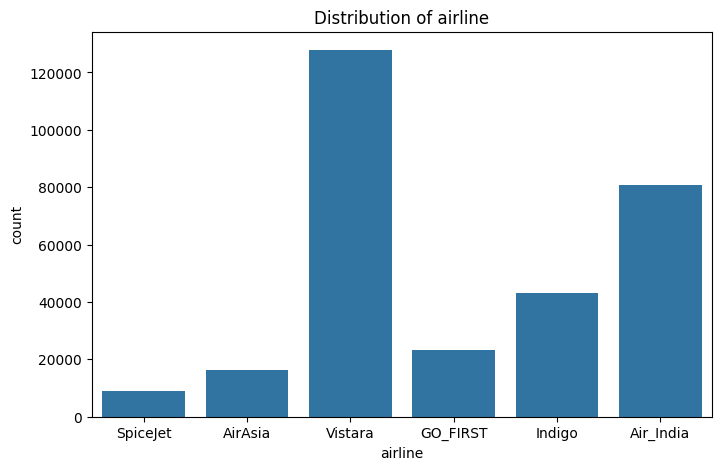

In [86]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['airline'])

plt.title("Distribution of airline")
plt.show()

**Flight**

In [87]:
df['flight'].nunique()

1561

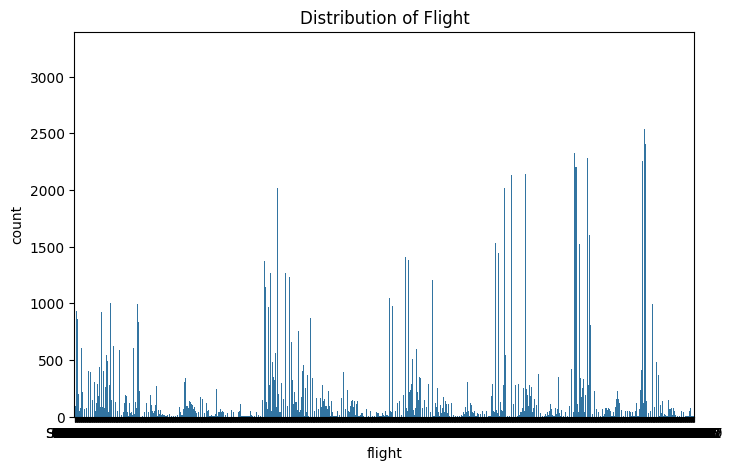

In [88]:
plt.figure(figsize=(8,5))
sns.countplot(data = df,x=df['flight'])

plt.title("Distribution of Flight")
plt.show()

# **Bivariate Analysis**

**Duration vs. Price**

In [89]:
fig = px.scatter(df,
                 x=df['duration'],
                 y=df['price'],
                 opacity=0.8,
                 title='Duration vs. Price')
fig.update_traces(marker_size=5)
fig.show()

**Days Left vs. Price**

In [90]:
fig = px.scatter(df,
                 x=df['days_left'],
                 y=df['price'],
                 opacity=0.8,
                 title='Days Left vs. Price')
fig.update_traces(marker_size=5)
fig.show()

# **Multivariate Analysis**

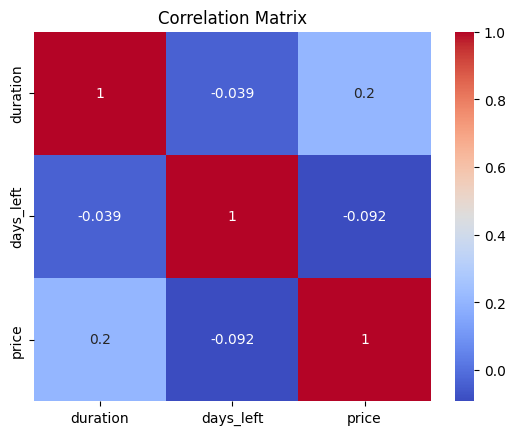

In [91]:
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', annot=True)
plt.title('Correlation Matrix');

# **Feature Engineering**

In [92]:
df.columns

Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left',
       'price'],
      dtype='object')

In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


## 1. Categorical Feature Encoding Strategy

Linear Regression requires all independent variables to be numeric and assumes a linear relationship between features and the target. To handle the categorical (`object`) columns appropriately, we apply different encoding techniques based on their cardinality and structure:

---
**A. Identifier / High-Cardinality Feature (`flight`)**
* **Action:** Drop the column.
* **Reasoning:** Contains specific flight route identifiers (e.g., `SG-8709`) with hundreds of unique values. One-hot encoding this feature would introduce extreme dimensionality, data sparsity, and severe overfitting without adding meaningful generalization.

---

**B. Binary & Ordinal Features (`class`, `stops`)**
* **Action:** Direct integer/ordinal mapping.
* **Reasoning:**
  * **`class`:** Follows a natural hierarchy (`Economy` vs. `Business`). Mapping to `0` and `1` directly isolates the baseline cost difference between classes within a single regression coefficient.
  * **`stops`:** Follows a logical ordered scale (`zero` $\rightarrow 0$, `one` $\rightarrow 1$, `two_or_more` $\rightarrow 2$). Numeric integer mapping preserves this sequence without expanding the feature space.

---

 **C. Nominal Features (`airline`, `source_city`, `destination_city`, `departure_time`, `arrival_time`)**
* **Action:** One-Hot Encoding (`pd.get_dummies` with `drop_first=True`).
* **Reasoning:**
  * These categories have no intrinsic order or ranking. Label encoding them numerically ($1, 2, 3\dots$) would falsely imply mathematical magnitudes (e.g., assuming category $3$ is three times the value of category $1$).
  * `drop_first=True` drops the reference dummy category to prevent the **dummy variable trap** (perfect multicollinearity), ensuring the feature matrix $X^T X$ remains invertible and stable for OLS estimation.

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   class             300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB


In [95]:
df_encoded = df.drop(columns=["flight"])

In [96]:
class_map = {
    "Economy": 0,
    "Business": 1
}

stops_map = {
    "zero": 0,
    "one": 1,
    "two_or_more": 2
}

df_encoded["class"] = df_encoded["class"].map(class_map)
df_encoded["stops"] = df_encoded["stops"].map(stops_map)

In [99]:
nominal_cols = [
    "airline",
    "source_city",
    "departure_time",
    "arrival_time",
    "destination_city"
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_cols,
    drop_first=True,
    dtype=int
)

In [100]:
df_encoded.head(3)

,stops,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai
0,0,0,2.17,1,5953,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
1,0,0,2.33,1,5953,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,1
2,0,0,2.17,1,5956,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1


In [101]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 30 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   stops                         300153 non-null  int64  
 1   class                         300153 non-null  int64  
 2   duration                      300153 non-null  float64
 3   days_left                     300153 non-null  int64  
 4   price                         300153 non-null  int64  
 5   airline_Air_India             300153 non-null  int64  
 6   airline_GO_FIRST              300153 non-null  int64  
 7   airline_Indigo                300153 non-null  int64  
 8   airline_SpiceJet              300153 non-null  int64  
 9   airline_Vistara               300153 non-null  int64  
 10  source_city_Chennai           300153 non-null  int64  
 11  source_city_Delhi             300153 non-null  int64  
 12  source_city_Hyderabad         300153 non-nul

# **Model Run and Evaluation**

**Only Using Numerical Value**

In [102]:
# Create inputs and targets
inputs, targets = df[['duration' , 'days_left']], df['price']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evalute the model
loss = root_mean_squared_error(targets, predictions)
print('Loss:', loss)

Loss: 22137.379595869246


**Using full Dataset**

In [103]:


# Create inputs and targets
inputs, targets = df_encoded.drop(columns=['price']), df_encoded['price']

# Create and train the model
model = LinearRegression().fit(inputs, targets)

# Generate predictions
predictions = model.predict(inputs)

# Compute loss to evaluate the model
loss = root_mean_squared_error(targets, predictions)
print('Loss:', loss)



Loss: 6810.048677071071
